In [ ]:
# 因为文件没有表头，通过 columns 参数明确告诉 DuckDB 这 5 列分别叫什么名字
# 这五列我已知晓存在，因此这么写
query_null = """
SELECT 
    COUNT(*) - COUNT(column0) AS null_user,
    COUNT(*) - COUNT(column1) AS null_item,
    COUNT(*) - COUNT(column2) AS null_category,
    COUNT(*) - COUNT(column3) AS null_behavior,
    COUNT(*) - COUNT(column4) AS null_timestamp
FROM read_csv_auto('UserBehavior.csv', header=False)
"""

df_null = duckdb.query(query_null).to_df()
print(df_null)

   null_user  null_item  null_category  null_behavior  null_timestamp
0          0          0              0              0               0


In [ ]:
# 在电商行为数据中，行为类型只有四种：pv、buy、cart、fav
# 在电商行为情境下，浏览最多，购买最少，可以先看漏斗
# 如果behavior_type的值不在这四种中，则认为是异常数据，进行过滤
import duckdb

# 按行为类型分组统计数量
query_behavior = """
SELECT 
    column3 AS behavior_type,
    COUNT(*) AS count
FROM read_csv_auto('UserBehavior.csv', header=False)
GROUP BY column3
ORDER BY count DESC
"""

df_behavior = duckdb.query(query_behavior).to_df()
print(df_behavior)

  behavior_type     count
0            pv  89716264
1          cart   5530446
2           fav   2888258
3           buy   2015839


In [ ]:
import duckdb

# 检查是否存在不合理的时间戳（比如小于 2017 年正常时间，或者大于合理范围的脏数据）
query_clean_time = """
SELECT 
    -- 统计时间戳小于 1500000000（异常偏早的数据）的行数
    COUNT(CASE WHEN CAST(column4 AS BIGINT) < 1500000000 THEN 1 END) AS abnormal_early,
    -- 统计时间戳大于 1600000000（异常偏后的数据）的行数
    COUNT(CASE WHEN CAST(column4 AS BIGINT) > 1600000000 THEN 1 END) AS abnormal_late,
    -- 总行数
    COUNT(*) AS total_rows
FROM read_csv_auto('UserBehavior.csv', header=False)
"""

df_check = duckdb.query(query_clean_time).to_df()
print(df_check)

   abnormal_early  abnormal_late  total_rows
0             887            564   100150807


In [3]:
import duckdb

# 创建一个名为 cleaned_behavior 的干净数据视图
# 过滤掉所有时间戳小于 1500000000 或大于 1600000000 的脏数据
query_create_view = """
CREATE OR REPLACE VIEW cleaned_behavior AS 
SELECT 
    column0 AS user_id,
    column1 AS item_id,
    column2 AS category_id,
    column3 AS behavior_type,
    CAST(column4 AS BIGINT) AS timestamp
FROM read_csv_auto('UserBehavior.csv', header=False)
WHERE CAST(column4 AS BIGINT) >= 1500000000 
  AND CAST(column4 AS BIGINT) <= 1600000000
"""

# 执行创建视图
duckdb.query(query_create_view)

# 验证一下清洗后的总行数（应该正好比原来少那 1451 行）
df_cleaned_count = duckdb.query("SELECT COUNT(*) AS clean_total FROM cleaned_behavior").to_df()
print(df_cleaned_count)

   clean_total
0    100149356


In [7]:
import duckdb

# 使用子查询安全地计算完全重复的行数
query_dup = """
WITH unique_data AS (
    SELECT DISTINCT user_id, item_id, category_id, behavior_type, timestamp
    FROM cleaned_behavior
)
SELECT 
    (SELECT COUNT(*) FROM cleaned_behavior) AS total_rows,
    (SELECT COUNT(*) FROM unique_data) AS unique_rows,
    (SELECT COUNT(*) FROM cleaned_behavior) - (SELECT COUNT(*) FROM unique_data) AS duplicate_count
"""

df_dup = duckdb.query(query_dup).to_df()
print(df_dup)

   total_rows  unique_rows  duplicate_count
0   100149356    100149307               49


In [9]:
import duckdb

# 创建一个去重后的最终纯净视图：final_cleaned_behavior
# 使用 DISTINCT 确保这 5 个字段完全相同的行只保留一条
query_final_view = """
CREATE OR REPLACE VIEW final_cleaned_behavior AS 
SELECT DISTINCT 
    user_id, 
    item_id, 
    category_id, 
    behavior_type, 
    timestamp
FROM cleaned_behavior
"""

duckdb.query(query_final_view)

# 验证最终落盘的绝对干净行数
df_final = duckdb.query("SELECT COUNT(*) AS final_total FROM final_cleaned_behavior").to_df()
print(df_final)

   final_total
0    100149307


In [8]:
import duckdb
select_pv_uv = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    COUNT(*) AS pv,
    COUNT(DISTINCT user_id) AS uv
FROM final_cleaned_behavior
WHERE behavior_type = 'pv'
"""
df_pv_uv = duckdb.query(select_pv_uv).to_df()
print(df_pv_uv)

         pv      uv
0  89714796  984114


In [9]:
import duckdb
select_fav = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    COUNT(*) AS fav
FROM final_cleaned_behavior
WHERE behavior_type = 'fav'
"""
df_fav = duckdb.query(select_fav).to_df()
print(df_fav)

       fav
0  2888258


In [ ]:
import duckdb
select_avg_pv = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    COUNT(DISTINCT user_id) AS X,
    COUNT(*) AS Y,
    (COUNT(*) * 1.0 / COUNT(DISTINCT user_id)) AS avg_pv_per_user
FROM final_cleaned_behavior
WHERE behavior_type = 'pv'
"""
df_avg_pv = duckdb.query(select_avg_pv).to_df()
print(df_avg_pv)



        X         Y  avg_pv_per_user
0  984114  89714796        91.163012


: 

In [2]:
import duckdb

# 按小时（0-23点）统计用户的活跃情况
query_hourly_activity = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    -- 1. 将 Unix 时间戳转换为时间，并提取出“小时”（0 到 23）
    EXTRACT(HOUR FROM to_timestamp(timestamp)) AS hour_of_day,
    
    -- 2. 统计该小时的总浏览次数 (PV)
    COUNT(*) AS pv,
    
    -- 3. 统计该小时的独立访客数 (UV)
    COUNT(DISTINCT user_id) AS uv

FROM final_cleaned_behavior
WHERE behavior_type = 'pv'
GROUP BY hour_of_day
ORDER BY hour_of_day ASC
"""

df_hourly = duckdb.query(query_hourly_activity).to_df()
print(df_hourly)

    hour_of_day       pv      uv
0             0  3058084  307110
1             1  1422140  161455
2             2   769475   94740
3             3   525157   68735
4             4   449813   61859
5             5   581811   81404
6             6  1226943  172803
7             7  2229479  316677
8             8  3043033  425860
9             9  3729381  497907
10           10  4335918  552874
11           11  4214925  561982
12           12  4257428  568479
13           13  4655639  578601
14           14  4643687  570022
15           15  4808655  581128
16           16  4609919  574946
17           17  4205880  562083
18           18  4316134  561152
19           19  5434279  602956
20           20  6590482  642223
21           21  7544066  662799
22           22  7450227  630782
23           23  5612241  498927


In [16]:
import duckdb
query_popular_items = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
    select 
    item_id,
    count(*) as fav_count
    from final_cleaned_behavior
    where behavior_type = 'fav'
    group by item_id
    order by fav_count desc
    limit 20
"""
df_popular_items = duckdb.query(query_popular_items).to_df()
print(df_popular_items)


    item_id  fav_count
0   2279428        971
1    812879        875
2   2331370        873
3   2818406        822
4   3330337        710
5   3845720        702
6   1535294        675
7    138964        642
8   2453685        636
9   2364679        621
10  1583704        578
11  1783990        556
12  1419997        534
13  2032668        517
14  3031354        513
15  1343119        483
16  4649427        476
17   740947        474
18  3403645        469
19  2783905        453


In [18]:
import duckdb
query_popular_items_buy = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
    select 
    item_id,
    count(*) as buy_count
    from final_cleaned_behavior
    where behavior_type = 'buy'
    group by item_id
    order by buy_count desc
    limit 20
"""
df_popular_items_buy = duckdb.query(query_popular_items_buy).to_df()
print(df_popular_items_buy)

    item_id  buy_count
0   3122135       1408
1   3031354        950
2   3964583        675
3   2560262        665
4   2964774        629
5    740947        560
6   1910706        548
7   1116492        512
8    705557        497
9   4443059        493
10  1415828        488
11  1034594        481
12  1168232        465
13  3189426        453
14  4219087        442
15   265985        441
16   257772        404
17  1535294        402
18  2955846        394
19  5062984        391


In [ ]:
import duckdb
select_popular_pv = """
with final_cleaned_behavior as (
    SELECT DISTINCT
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        column4 AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    item_id,
    COUNT(*) AS pv_count
FROM final_cleaned_behavior
WHERE behavior_type = 'pv'      
GROUP BY item_id
ORDER BY pv_count DESC
LIMIT 20
"""
df_popular_items_pv = duckdb.query(select_popular_pv).to_df()
print(df_popular_items_pv)


    item_id  pv_count
0    812879     30094
1   3845720     25668
2    138964     21109
3   2331370     19490
4   2032668     19145
5   1535294     17841
6     59883     17409
7   4211339     17354
8   3031354     17182
9   3371523     17159
10  2338453     17071
11  2367945     16190
12  1591862     16185
13   987143     16003
14  2818406     15982
15  4649427     15150
16  1583704     14789
17  2453685     14577
18  2279428     14257
19  4443059     14086


In [20]:
import duckdb

query_item_funnel_top = """
WITH final_cleaned_behavior AS (
    SELECT DISTINCT 
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        CAST(column4 AS BIGINT) AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000 
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    item_id,
    COUNT(CASE WHEN behavior_type = 'pv' THEN 1 END) AS pv_count,
    COUNT(CASE WHEN behavior_type = 'fav' THEN 1 END) AS fav_count,
    COUNT(CASE WHEN behavior_type = 'buy' THEN 1 END) AS buy_count
FROM final_cleaned_behavior
GROUP BY item_id
ORDER BY pv_count DESC
LIMIT 20
"""

df_result = duckdb.query(query_item_funnel_top).to_df()
print(df_result)

    item_id  pv_count  fav_count  buy_count
0    812879     30094        875        136
1   3845720     25668        702        105
2    138964     21109        642         95
3   2331370     19490        873        163
4   2032668     19145        517         57
5   1535294     17841        675        402
6     59883     17409        273         39
7   4211339     17354        412         65
8   3031354     17182        513        950
9   3371523     17159         14          7
10  2338453     17071        389        246
11  2367945     16190          1          0
12  1591862     16185          2          0
13   987143     16003        447         55
14  2818406     15982        822         95
15  4649427     15150        476         65
16  1583704     14789        578        142
17  2453685     14577        636        197
18  2279428     14257        971        124
19  4443059     14086        334        493


In [5]:
import sys
!{sys.executable} -m pip install matplotlib -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------------------------------------

    pv_uv  fav_uv  cart_uv  buy_uv
0  984114  389823   738996  672404


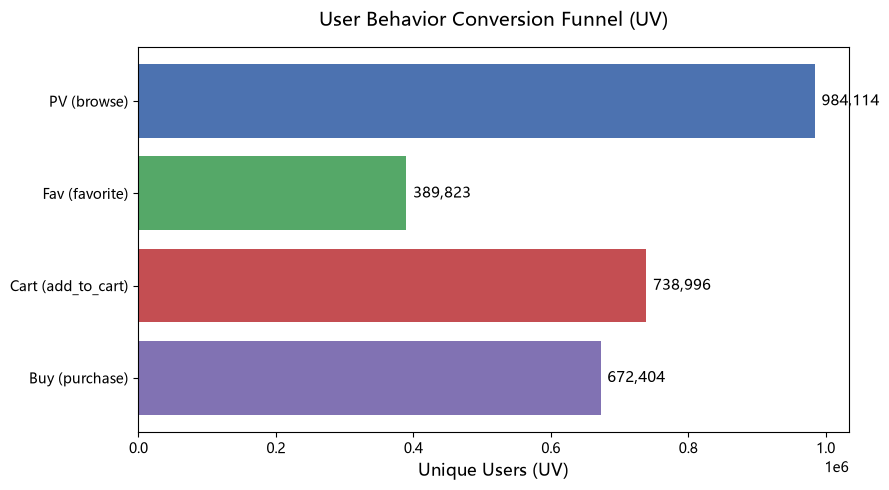

In [8]:
import duckdb

query_funnel = """
WITH final_cleaned_behavior AS (
    SELECT DISTINCT 
        column0 AS user_id,
        column1 AS item_id,
        column2 AS category_id,
        column3 AS behavior_type,
        CAST(column4 AS BIGINT) AS timestamp
    FROM read_csv_auto('UserBehavior.csv', header=False)
    WHERE CAST(column4 AS BIGINT) >= 1500000000 
      AND CAST(column4 AS BIGINT) <= 1600000000
)
SELECT 
    COUNT(DISTINCT CASE WHEN behavior_type = 'pv' THEN user_id END) AS pv_uv,
    COUNT(DISTINCT CASE WHEN behavior_type = 'fav' THEN user_id END) AS fav_uv,
    COUNT(DISTINCT CASE WHEN behavior_type = 'cart' THEN user_id END) AS cart_uv,
    COUNT(DISTINCT CASE WHEN behavior_type = 'buy' THEN user_id END) AS buy_uv
FROM final_cleaned_behavior
"""

df_funnel = duckdb.query(query_funnel).to_df()
print(df_funnel)

import matplotlib.pyplot as plt

# 1. 准备画图的数据（把 DataFrame 的单行数据转成列表）
stages = ['PV (browse)', 'Fav (favorite)', 'Cart (add_to_cart)', 'Buy (purchase)']
values = [
    df_funnel['pv_uv'].values[0],
    df_funnel['fav_uv'].values[0],
    df_funnel['cart_uv'].values[0],
    df_funnel['buy_uv'].values[0]
]

# 2. 开始画图
plt.figure(figsize=(9, 5))
bars = plt.barh(stages, values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B3'])

# 3. 在柱子后面标上具体的数字和转化率
for bar in bars:
    width = bar.get_width()
    plt.text(width + (max(values) * 0.01), bar.get_y() + bar.get_height()/2, 
             f'{width:,}', 
             va='center', fontsize=11)

# 4. 图表美化
plt.title('User Behavior Conversion Funnel (UV)', fontsize=14, pad=15)
plt.xlabel('Unique Users (UV)', fontsize=12)
plt.gca().invert_yaxis()  # 让浏览在最上面，购买在最下面，符合漏斗直觉
plt.tight_layout()

# 5. 展示
plt.show()

import matplotlib.pyplot as plt

# 解决 Matplotlib 中文乱码和警告问题
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']  # 设置微软雅黑
plt.rcParams['axes.unicode_minus'] = False             # 解决负号 '-' 显示为方块的问题